  INSTITUTIONAL ENSEMBLE PORTFOLIO OPTIMISER v4.3
  Base Currency: USD | DCF Horizon: 2.0y | Walk-Forward Folds: 5

[0] Risk-free rate
  ✓ Live 13-wk T-bill (^IRX): 3.9780%

[1] Downloading price data & auditing history length...
  ✓ 21 assets | 1242 trading days (4.93 yrs) | 2021-11-02 → 2026-10-30

[2] Single-pass metadata fetch (FX-adjusted market caps & verified analyst targets)...
  ✓ 21 FX-adjusted market caps & 21/21 verified analyst targets ready

██████████████████████████████████████████████████████████████████████████████
  PHASE 1 — EXPANDING-WINDOW WALK-FORWARD MECHANICS & CALIBRATION
  Purpose : Test optimizer mechanics across expanding OOS folds (no target leak)
  Design  : 40% burn-in + 5 expanding OOS folds (drifting buy-and-hold)
██████████████████████████████████████████████████████████████████████████████

[P1.1] Running 5-Fold Expanding-Window Walk-Forward...
  • Fold 1/5 │ Train: 2021-11-02 → 2023-10-26 (496d) │ OOS: 2023-10-27 → 2024-06-05 (149d)
  • Fold 2/5 │ T

/tmp/ipykernel_3137/2962930651.py:1235: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0, 1, 0.95])


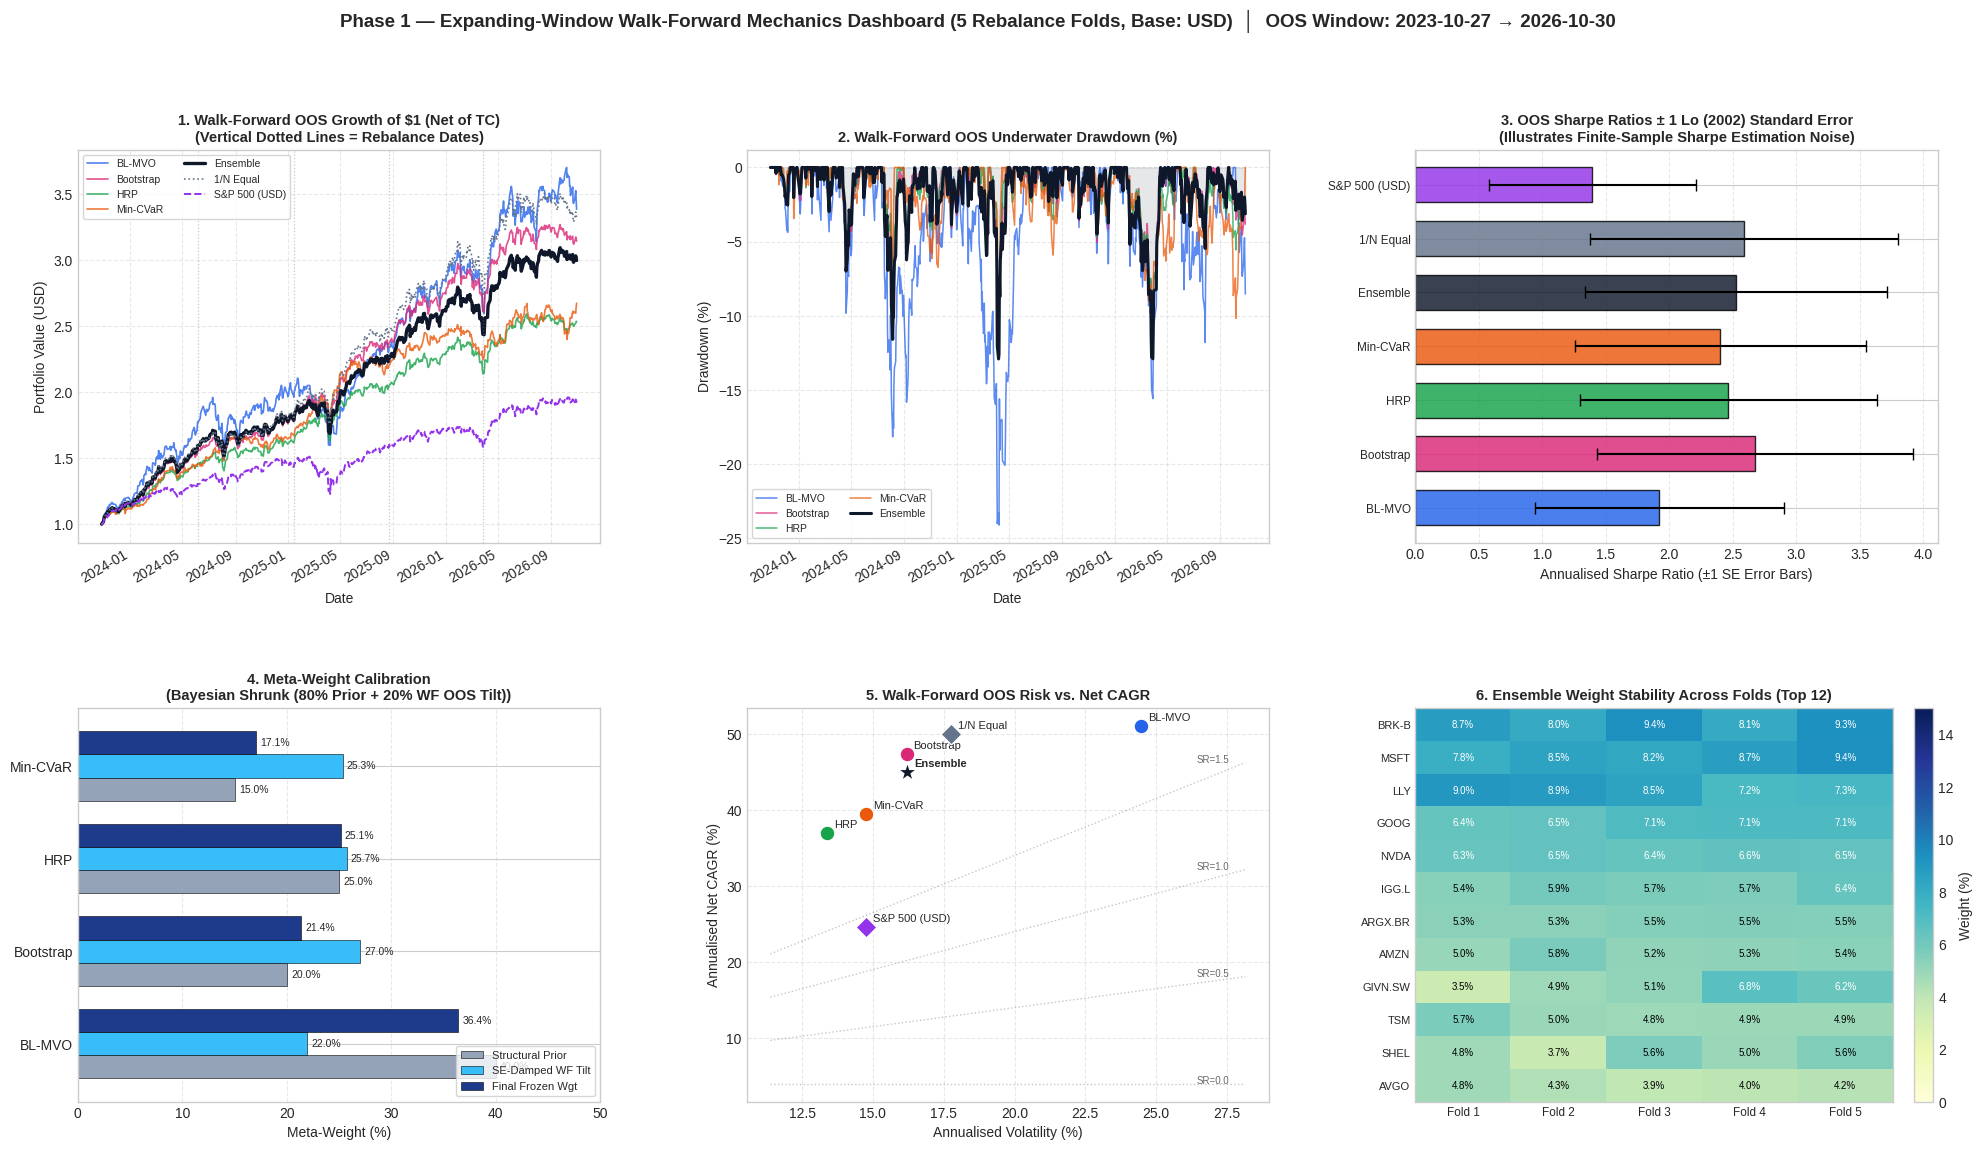

  ✓ Phase 1 dashboard saved → phase1_walkforward_mechanics.png

██████████████████████████████████████████████████████████████████████████████
  PHASE 2 — PRODUCTION, VALUATION AUDIT & LIVE PREDICTION
  Purpose : Audit DCF vs. Analyst expected returns & generate live weights
  Data    : Full history (1242 daily / 261 weekly obs)
  Views   : Horizon-adjusted DCF (2.0y) + Analyst (1.0y) with disagreement penalty
  Weights : [BL-MVO: 36.4% | Bootstrap: 21.4% | HRP: 25.1% | Min-CVaR: 17.1%]
██████████████████████████████████████████████████████████████████████████████

[P2.1] Building live BL posterior & auditing DCF vs. Analyst expected returns (as of 2026-10-30)...

════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════════
  VALUATION & EXPECTED RETURN AUDIT TABLE  │  DCF Horizon: 2.0y (Annualised)  │  Analyst Horizon: 1.0y  │  Clip Bounds: [-50%, +100%]
════════════════════════════════════════════

/tmp/ipykernel_3137/2962930651.py:1472: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0, 1, 0.95])


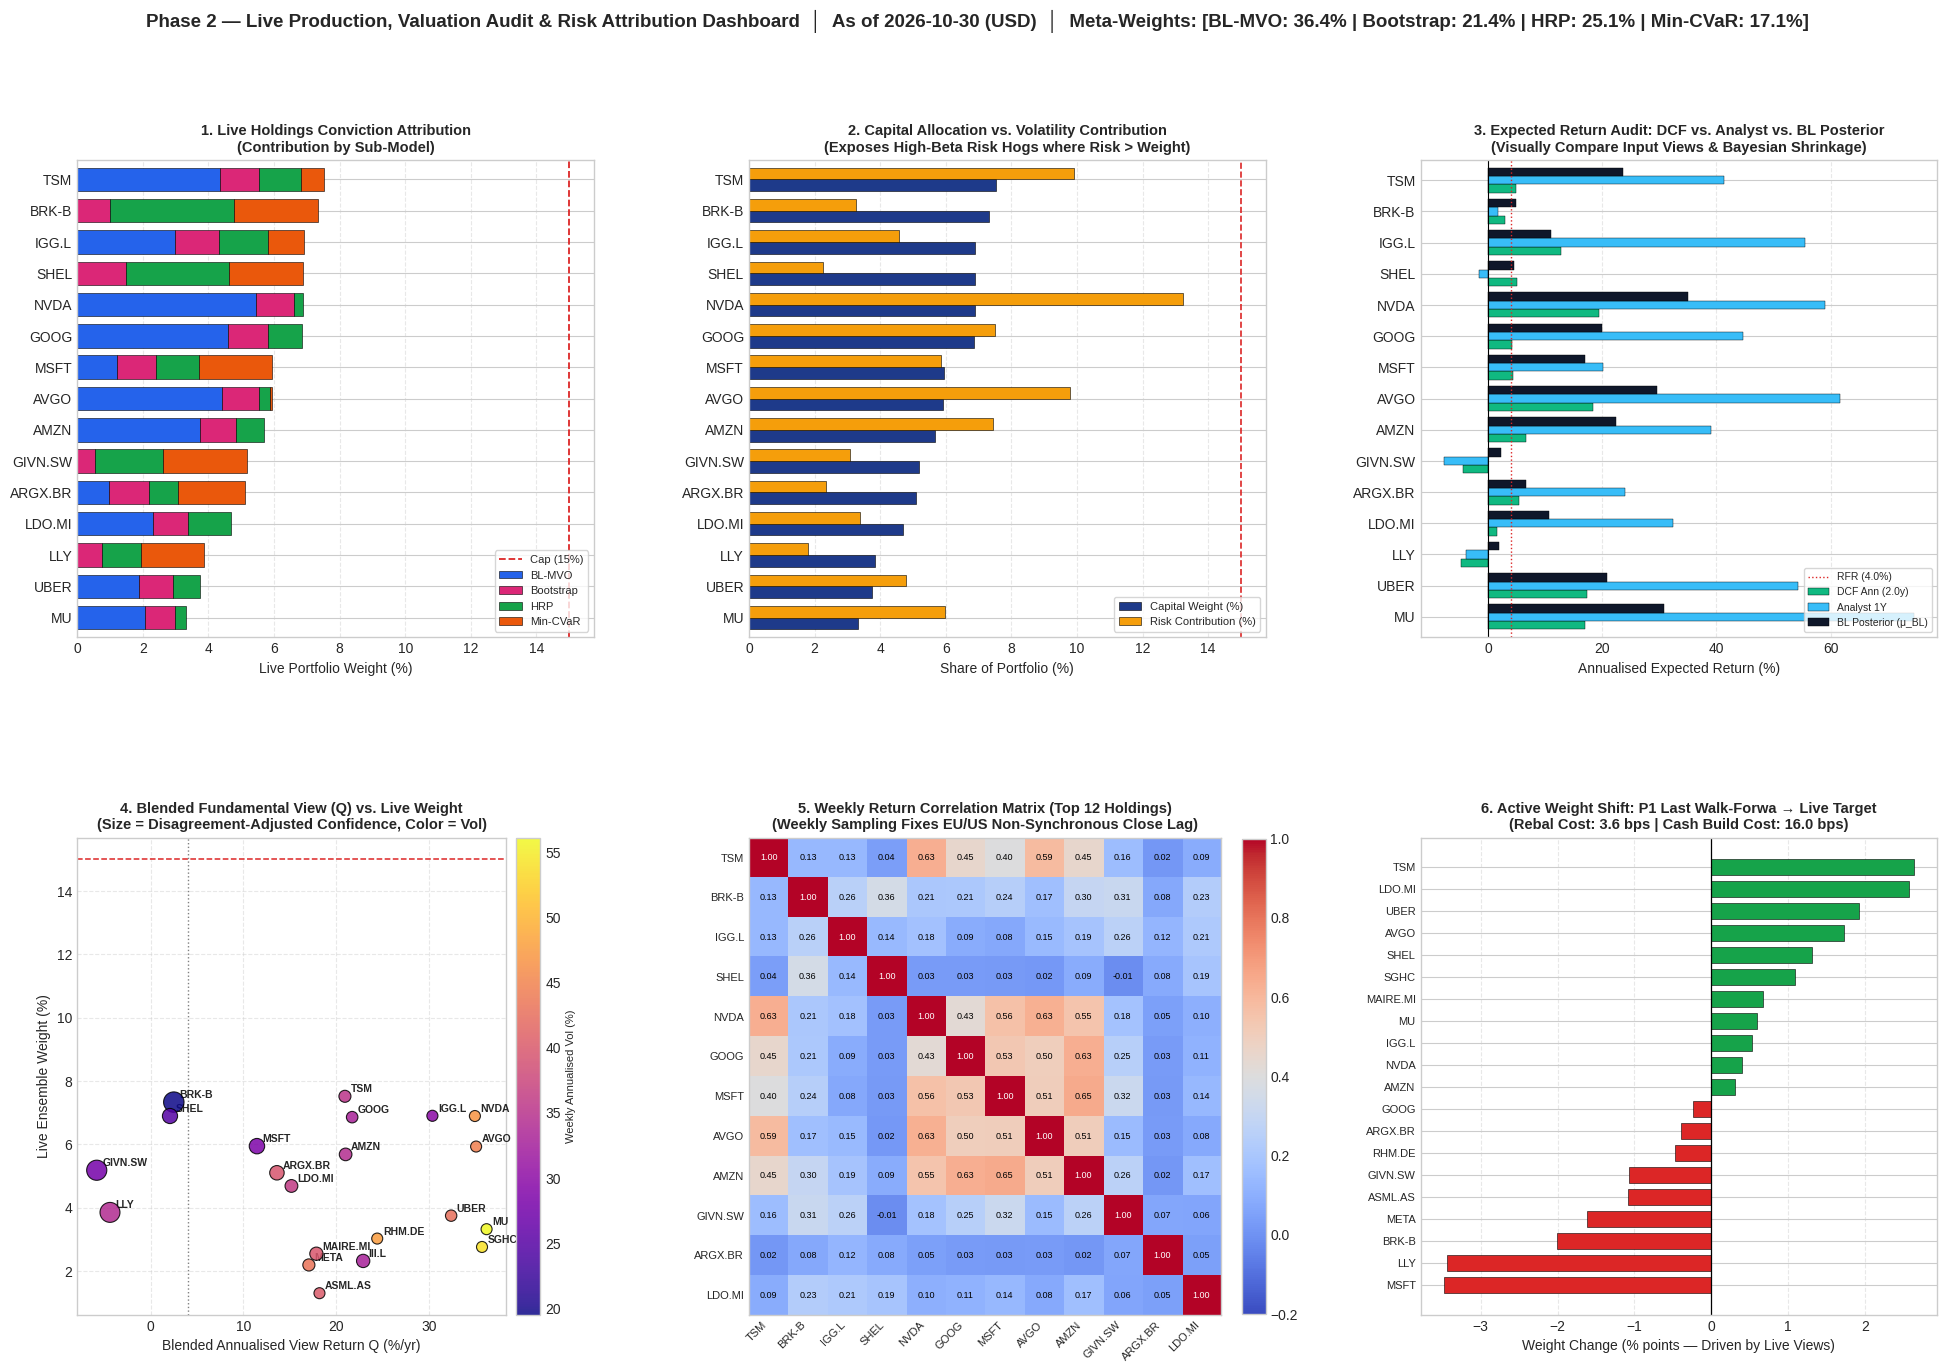

  ✓ Phase 2 dashboard saved → phase2_live_production.png

  RUN COMPLETE
  Phase 1 — 5-Fold OOS Ensemble Sharpe : 2.524 (±1.189 SE)
  Phase 1 — Stitched OOS Window        : 2023-10-27 → 2026-10-30
  Phase 2 — Live Holdings              : 21 positions (Max: 7.52%)
  Phase 2 — Initial Build Cost (Cash)  : 16.0 bps
  Phase 2 — Rebalance Cost             : 3.6 bps (Turnover: 13.8%)
  Meta-weights (frozen)                : [BL-MVO: 36.4% | Bootstrap: 21.4% | HRP: 25.1% | Min-CVaR: 17.1%]


In [ ]:
"""
Institutional Portfolio Optimiser v4.3 — Walk-Forward, Valuation Audit & Live Production
========================================================================================

PHASE 1 │ Walk-Forward Mechanics & Meta-Weight Calibration (No Target Leakage)
  Purpose : Validate optimizer mechanics across expanding out-of-sample folds.
  Method  : 40% initial burn-in → 5 expanding walk-forward OOS rebalance folds.
            Evaluates true buy-and-hold drifting returns net of rebalancing costs.
            Computes Lo (2002) Sharpe standard errors & Prior-Shrunk meta-weights.
  Views   : Equilibrium priors only in Phase 1 (prevents backward target leakage).
  Output  : FROZEN_META_WEIGHTS — passed into Phase 2.

PHASE 2 │ Production, Valuation Audit & Live Prediction
  Purpose : Validate DCF & Analyst expected returns and generate live deployment weights.
  Data    : 100% of available weekly & daily history.
  Views   : Today's prices vs horizon-adjusted DCF (2.5y) & Analyst (1.0y) targets,
            with full diagnostic printout, anomaly scanner, and disagreement penalty.
  Weights : Frozen meta_weights from Phase 1.
  Output  : Valuation Audit Table + Live allocation weights + Euler risk attribution.
"""

import warnings
import numpy as np
import pandas as pd
import yfinance as yf
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec

from pypfopt import risk_models, black_litterman, BlackLittermanModel
from pypfopt.efficient_frontier import EfficientFrontier, EfficientCVaR
from pypfopt.hierarchical_portfolio import HRPOpt

# Filter only noisy library deprecation/future warnings; keep PyPortfolioOpt solver warnings visible
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=DeprecationWarning)
warnings.filterwarnings("ignore", message=".*auto_adjust.*")


# ══════════════════════════════════════════════════════════════════════════════
# 1 │ USER PARAMETERS
# ══════════════════════════════════════════════════════════════════════════════

US_TICKERS = [
    "BRK-B", "GOOG", "MSFT", "SHEL", "UBER", #"GCT",
    "NVDA", "MU", "META", "SGHC", "LLY", "TSM", "AMZN", "AVGO",
]

NON_US_TICKERS = {
    "GIVN.SW":  "CHFUSD=X",
    "IGG.L":    "GBPUSD=X",
    "III.L":    "GBPUSD=X",
    "ARGX.BR":  "EURUSD=X",
    "LDO.MI":   "EURUSD=X",
    "RHM.DE":   "EURUSD=X",
    "MAIRE.MI": "EURUSD=X",
    "ASML.AS":  "EURUSD=X",
}

EXPECTED_TRADING_CURRENCY = {
    "GIVN.SW": "CHF", "IGG.L": "GBp", "III.L": "GBp",
    "ARGX.BR": "EUR", "LDO.MI": "EUR", "RHM.DE": "EUR",
    "MAIRE.MI": "EUR", "ASML.AS": "EUR",
}

DCF_TARGETS = {
    # .L tickers: pence (GBp) | European/Swiss: local currency | US: USD
    "BRK-B":    580,  "GOOG":     303,  "MSFT":     570,  "SHEL":     120,
    "UBER":      90,  "GCT":       65,  "NVDA":     295,  "MU":      1225,
    "META":     650,  "SGHC":      14,  "LLY":     1300,  "TSM":      455,
    "AMZN":     272,  "AVGO":     460,
    "GIVN.SW": 3650,  "IGG.L":   1210,  "III.L":   3000,  "ARGX.BR":  900,
    "LDO.MI":    53,  "RHM.DE":  1180,  "MAIRE.MI": 14.4,  "ASML.AS": 1350,
}

# Base currency for portfolio evaluation ("USD" or "EUR")
BASE_CURRENCY     = "USD"     # Set to "EUR" to evaluate all risk/returns in Euros
DCF_HORIZON_YEARS = 2.0       # Years for price to converge to DCF intrinsic value (vs 1.0y for Analysts)
UPSIDE_CLIP       = (-0.50, 1.00)  # Annualized expected return guardrails (-50%/yr to +100%/yr)

MIN_W             = 0.00
MAX_W             = 0.15     # Single-name hard cap (10%)
FALLBACK_RFR      = 0.035
PERIOD            = "5y"      # Downloads up to 5y; automatically audits youngest ticker truncation
N_BOOTSTRAP       = 400
RANDOM_SEED       = 52

# ── Expanding-Window Walk-Forward Parameters (Phase 1) ───────────────────────
INITIAL_TRAIN_FRAC = 0.40     # Initial burn-in training window (40% of history)
N_WF_FOLDS         = 5        # Number of expanding-window out-of-sample rebalance folds

# ── Meta-Weighting Configuration ─────────────────────────────────────────────
# Options: "shrunk" (Recommended), "hardcoded", "dynamic"
META_WEIGHT_MODE = "shrunk"
SHRINKAGE_LAMBDA = 0.20       # 80% Structural Prior + max 20% Walk-Forward OOS Sharpe tilt

STRUCTURAL_PRIOR = {
    "BL-MVO":    0.40,        # Core fundamental conviction + covariance
    "Bootstrap": 0.20,        # Resampled BL conviction (tau = 1/T_years)
    "HRP":       0.25,        # Weekly hierarchical cluster diversification
    "Min-CVaR":  0.15,        # Weekly left-tail drawdown protection
}

# Optional: Enter actual current holdings (weights summing to <= 1.0) for Phase 2 turnover calculation.
CURRENT_HOLDINGS: dict = {}

FALLBACK_MCAPS_USD: dict = {
    "GIVN.SW":  42_000_000_000,   "IGG.L":      4_500_000_000,
    "III.L":    40_000_000_000,   "ARGX.BR":   35_000_000_000,
    "LDO.MI":   18_000_000_000,   "RHM.DE":    45_000_000_000,
    "ASML.AS": 320_000_000_000,   "MAIRE.MI":   3_000_000_000,
    "BRK-B": 1_000_000_000_000,   "GOOG":   2_200_000_000_000,
    "MSFT":  3_100_000_000_000,   "NVDA":   3_300_000_000_000,
    "META":  1_500_000_000_000,   "AMZN":   2_100_000_000_000,
    "TSM":     900_000_000_000,   "LLY":      800_000_000_000,
    "SHEL":    220_000_000_000,   "UBER":     160_000_000_000,
    "MU":      150_000_000_000,   "AVGO":   1_050_000_000_000,
    "SYK":     140_000_000_000,   "GCT":        1_000_000_000,
    "SGHC":      2_500_000_000,
}

# Realistic one-way transaction costs (bps), including UK Stamp Duty (.L) & Italian FTT (.MI) + FX spread
COST_MAP: dict = {
    "NVDA":  7,   "MSFT":  7,   "AMZN":  7,   "META":  7,
    "GOOG":  7,   "AVGO":  8,   "LLY":   8,   "BRK-B": 8,
    "SYK":   8,   "TSM":   9,   "UBER":  9,   "SHEL": 10,
    "MU":   10,   "ASML.AS": 15, "RHM.DE": 15, "GIVN.SW": 18,
    "ARGX.BR": 18, "LDO.MI": 25, "MAIRE.MI": 35,
    "III.L": 55,  "IGG.L": 60,  "SGHC": 25,   "GCT": 30,
}
DEFAULT_BPS = 12.0

ALL_TICKERS = US_TICKERS + list(NON_US_TICKERS.keys())
WB          = (MIN_W, MAX_W)


# ══════════════════════════════════════════════════════════════════════════════
# 2 │ HELPER FUNCTIONS
# ══════════════════════════════════════════════════════════════════════════════

def get_live_risk_free_rate(fallback: float = 0.035) -> float:
    try:
        raw = yf.download("^IRX", period="5d", progress=False)["Close"].dropna()
        if not raw.empty:
            rate = float(np.asarray(raw.iloc[-1]).ravel()[0]) / 100.0
            print(f"  ✓ Live 13-wk T-bill (^IRX): {rate:.4%}")
            return rate
    except Exception:
        pass
    print(f"  ⚠ Could not fetch live rate — using fallback: {fallback:.4%}")
    return fallback


def calculate_view_confidence(
    ann_upside: float,
    base_conf:  float = 0.50,
    asset_vol:  float = 0.30,
) -> float:
    """Assigns highest confidence to plausible views; penalizes extreme outliers & high volatility."""
    abs_up = abs(float(ann_upside))
    # Penalize extreme annualized upsides (> 40%/yr) as likely model/target noise
    extremity_penalty = max(0.0, (abs_up - 0.40) * 0.35)
    # Penalize high-volatility stocks where point fair-value targets have wide error bars
    vol_penalty = max(0.0, (asset_vol - 0.25) * 0.25)
    conf = base_conf - extremity_penalty - vol_penalty
    return float(np.clip(conf, 0.15, 0.65))


def combine_views_and_confidences(
    raw_views: list[tuple[str, float, float]],
    min_c:     float = 0.15,
    max_c:     float = 0.65,
) -> tuple[float, float, str]:
    """Combines DCF and Analyst views while PENALIZING confidence when sources disagree."""
    if len(raw_views) == 1:
        source, q, c = raw_views[0]
        status = "DCF Only" if "DCF" in source else "Anl Only"
        return float(q), float(np.clip(c, min_c, max_c)), status

    total_c = sum(v[2] for v in raw_views)
    blended_q = sum(v[1] * v[2] for v in raw_views) / total_c

    q_vals = [v[1] for v in raw_views]
    c_vals = [v[2] for v in raw_views]
    avg_c  = float(np.mean(c_vals))

    spread = abs(q_vals[0] - q_vals[1])
    same_sign = (q_vals[0] * q_vals[1]) >= 0

    if same_sign and spread <= 0.15:
        # Confirmation boost when DCF and Analysts agree in direction and magnitude
        combined_c = avg_c + 0.12 * min(c_vals) * (1.0 - spread / 0.15)
        status = "✓ Agree"
    elif same_sign:
        # Same sign, but wide gap (>15%/yr difference) -> moderate damping
        penalty_factor = np.exp(-2.2 * spread) * 0.90
        combined_c = avg_c * penalty_factor
        status = "~ Diverge"
    else:
        # Opposite signs (one bullish, one bearish) -> strong disagreement penalty
        penalty_factor = np.exp(-2.2 * spread) * 0.70
        combined_c = avg_c * penalty_factor
        status = "⚠ Conflict"

    return float(blended_q), float(np.clip(combined_c, min_c, max_c)), status


def enforce_weight_bounds(weights_dict: dict, max_w: float) -> dict:
    """Iteratively clips weights at max_w and redistributes excess proportionally."""
    w = pd.Series(weights_dict, dtype=float)
    w = w[w > 0]
    if w.empty or w.sum() <= 0:
        return weights_dict
    w = w / w.sum()

    for _ in range(50):
        if w.max() <= max_w + 1e-6:
            break
        capped = w >= max_w
        if capped.all():
            break
        w[capped] = max_w
        rem_mass = 1.0 - w[capped].sum()
        uncapped_sum = w[~capped].sum()
        if uncapped_sum > 0 and rem_mass > 0:
            w[~capped] = w[~capped] / uncapped_sum * rem_mass
        else:
            break
    return (w / w.sum()).to_dict()


def compute_transaction_cost(
    new_w:       pd.Series,
    prev_w:      pd.Series = None,
    cost_map:    dict       = COST_MAP,
    default_bps: float      = DEFAULT_BPS,
) -> tuple[float, float]:
    """Computes transaction cost and turnover. If prev_w is None, assumes initial build from cash."""
    new_s = pd.Series(new_w, dtype=float)
    if prev_w is None:
        tc_pct = float(sum(
            abs(new_s[t]) * cost_map.get(t, default_bps) / 10_000.0 for t in new_s.index
        ))
        return tc_pct, float(new_s.abs().sum())

    prev_s       = pd.Series(prev_w, dtype=float)
    tickers      = new_s.index.union(prev_s.index)
    new_aligned  = new_s.reindex(tickers).fillna(0.0)
    prev_aligned = prev_s.reindex(tickers).fillna(0.0)
    delta        = (new_aligned - prev_aligned).abs()

    tc_pct = float(sum(
        delta[t] * cost_map.get(t, default_bps) / 10_000.0 for t in tickers
    ))
    turnover = float(delta.sum()) / 2.0
    return tc_pct, turnover


def simulate_drifting_slice(
    target_weights: dict | pd.Series,
    returns_slice:  pd.DataFrame,
    prev_weights:   pd.Series = None,
    cost_map:       dict      = COST_MAP,
    default_bps:    float     = DEFAULT_BPS,
) -> tuple[pd.Series, pd.Series, pd.Series, float, float]:
    """Simulates a true Buy-and-Hold drifting portfolio over `returns_slice`."""
    cols = returns_slice.columns
    w = pd.Series(target_weights, dtype=float).reindex(cols).fillna(0.0)
    if w.sum() > 0:
        w = w / w.sum()

    tc_pct, turnover = compute_transaction_cost(w, prev_weights, cost_map, default_bps)

    asset_growth = (1.0 + returns_slice).cumprod()
    port_wealth_gross = asset_growth @ w

    r_gross = port_wealth_gross.pct_change()
    r_gross.iloc[0] = float(returns_slice.iloc[0] @ w)

    r_net = r_gross.copy()
    r_net.iloc[0] = (1.0 + r_gross.iloc[0]) * (1.0 - tc_pct) - 1.0

    final_wealth = float(port_wealth_gross.iloc[-1])
    if final_wealth > 0:
        end_weights = (w * asset_growth.iloc[-1]) / final_wealth
    else:
        end_weights = w

    return r_net, r_gross, end_weights, tc_pct, turnover


def summarize_return_series(
    r_net:         pd.Series,
    r_gross:       pd.Series,
    rfr:           float,
    total_tc_pct:  float = 0.0,
    avg_turnover:  float = np.nan,
) -> dict:
    """Computes Geometric CAGR, Volatility, Lo (2002) Sharpe SE, Max DD, CVaR-95, and Calmar."""
    n_days = len(r_net)
    years  = max(n_days / 252.0, 1e-6)

    cum_net   = (1.0 + r_net).cumprod()
    cum_gross = (1.0 + r_gross).cumprod()

    ann_ret_net   = float(cum_net.iloc[-1] ** (1.0 / years) - 1.0) if cum_net.iloc[-1] > 0 else -1.0
    ann_ret_gross = float(cum_gross.iloc[-1] ** (1.0 / years) - 1.0) if cum_gross.iloc[-1] > 0 else -1.0
    ann_vol       = float(r_net.std() * np.sqrt(252))

    sharpe = (ann_ret_net - rfr) / ann_vol if ann_vol > 0 else np.nan
    sharpe_se = float(np.sqrt((1.0 + 0.5 * (sharpe ** 2)) / years)) if pd.notna(sharpe) else np.nan

    max_dd = float(((cum_net - cum_net.cummax()) / cum_net.cummax()).min())
    var5   = np.percentile(r_net, 5)
    cvar95 = float(r_net[r_net <= var5].mean() * np.sqrt(252))
    calmar = ann_ret_net / abs(max_dd) if max_dd != 0 else np.nan

    return {
        "Ann. Return (net)":   ann_ret_net,
        "Ann. Return (gross)": ann_ret_gross,
        "Ann. Volatility":     ann_vol,
        "Sharpe":              sharpe,
        "Sharpe SE":           sharpe_se,
        "Max Drawdown":        max_dd,
        "CVaR-95 (ann.)":      cvar95,
        "Calmar":              calmar,
        "Avg Turnover":        avg_turnover,
        "Total TC (bps)":      total_tc_pct * 10_000,
        "TC Drag (ann. bps)":  (total_tc_pct / years) * 10_000,
    }


def michaud_bootstrap(
    returns_weekly: pd.DataFrame,
    bl_returns:     pd.Series,
    bl_cov:         pd.DataFrame,
    weight_bounds:  tuple,
    rfr:            float,
    n_iter:         int = 200,
    seed:           int = RANDOM_SEED,
) -> dict:
    """Michaud Resampled Efficiency using weekly returns and dynamic tau = 1 / T_years."""
    rng = np.random.default_rng(seed)
    collected = []
    n_weeks = len(returns_weekly)
    t_years = max(n_weeks / 52.0, 1.0)
    tau = 1.0 / t_years

    tickers = list(returns_weekly.columns)
    mu_bl   = bl_returns.reindex(tickers).values
    cov_bl  = bl_cov.reindex(index=tickers, columns=tickers).values

    for _ in range(n_iter):
        try:
            rs = returns_weekly.sample(
                n=n_weeks, replace=True, random_state=int(rng.integers(10**9))
            )
            S_rs = risk_models.CovarianceShrinkage(rs, returns_data=True, frequency=52).ledoit_wolf()

            mu_sim = pd.Series(
                rng.multivariate_normal(mean=mu_bl, cov=tau * cov_bl),
                index=tickers,
            )

            ef = EfficientFrontier(mu_sim, S_rs, weight_bounds=weight_bounds)
            if (mu_sim > rfr).any():
                ef.max_sharpe(risk_free_rate=rfr)
            else:
                ef.min_volatility()
            collected.append(pd.Series(ef.clean_weights()))
        except Exception:
            continue

    if not collected:
        eq = 1.0 / len(tickers)
        return {t: eq for t in tickers}

    avg = pd.DataFrame(collected).mean()
    avg = avg / avg.sum()
    return enforce_weight_bounds(avg.round(6).to_dict(), weight_bounds[1])


def build_bl_posterior(
    prices_window:       pd.DataFrame,
    sp500_window:        pd.Series,
    mcaps_base:          dict,
    tickers:             list,
    local_prices_window: pd.Series,
    dcf_targets:         dict,
    analyst_targets:     dict,
    rfr:                 float,
    dcf_horizon:         float = DCF_HORIZON_YEARS,
    upside_clip:         tuple = UPSIDE_CLIP,
) -> tuple:
    """Builds Black-Litterman posterior and full DCF vs. Analyst diagnostic table."""
    weekly_prices = prices_window.resample("W-FRI").last().dropna(how="all")
    S_lw = risk_models.CovarianceShrinkage(weekly_prices, frequency=52).ledoit_wolf()
    asset_vols = pd.Series(np.sqrt(np.diag(S_lw)), index=S_lw.index)

    try:
        sp_weekly = sp500_window.resample("W-FRI").last().dropna()
        raw_delta = float(black_litterman.market_implied_risk_aversion(
            sp_weekly, frequency=52, risk_free_rate=rfr
        ))
        delta = 2.5 if (np.isnan(raw_delta) or raw_delta <= 0) else float(np.clip(raw_delta, 1.5, 4.5))
    except Exception:
        delta = 2.5

    mkt_prior = black_litterman.market_implied_prior_returns(
        mcaps_base, delta, S_lw, risk_free_rate=rfr
    )

    P_rows, Q_vals, conf_vals, view_log = [], [], [], []
    audit_records = {}

    for idx, t in enumerate(tickers):
        raw_views = []
        px = float(local_prices_window[t]) if t in local_prices_window.index else np.nan
        vol_t = float(asset_vols.get(t, 0.30))
        ccy = EXPECTED_TRADING_CURRENCY.get(t, "USD")

        dcf_tgt     = float(dcf_targets[t]) if (t in dcf_targets and dcf_targets[t] > 0) else np.nan
        dcf_raw_up  = np.nan
        dcf_ann_raw = np.nan
        dcf_ann_clp = np.nan
        dcf_clipped = False
        dcf_conf    = np.nan

        anl_tgt     = float(analyst_targets[t]) if (t in analyst_targets and analyst_targets[t] > 0) else np.nan
        anl_raw_up  = np.nan
        anl_1y_clp  = np.nan
        anl_clipped = False
        anl_conf    = np.nan

        if pd.notna(px) and px > 0:
            # 1. DCF View: Annualized over DCF_HORIZON_YEARS
            if pd.notna(dcf_tgt):
                dcf_raw_up  = (dcf_tgt - px) / px
                dcf_ann_raw = ((dcf_tgt / px) ** (1.0 / dcf_horizon)) - 1.0
                dcf_ann_clp = float(np.clip(dcf_ann_raw, upside_clip[0], upside_clip[1]))
                dcf_clipped = abs(dcf_ann_raw - dcf_ann_clp) > 1e-6
                dcf_conf    = calculate_view_confidence(dcf_ann_clp, base_conf=0.52, asset_vol=vol_t)
                raw_views.append(("DCF_Ann", dcf_ann_clp, dcf_conf))

            # 2. Analyst View: 12-Month Target (1-Year Horizon)
            if pd.notna(anl_tgt):
                anl_raw_up = (anl_tgt - px) / px
                if -0.65 <= anl_raw_up <= 1.80:
                    anl_1y_clp  = float(np.clip(anl_raw_up, upside_clip[0], upside_clip[1]))
                    anl_clipped = abs(anl_raw_up - anl_1y_clp) > 1e-6
                    anl_conf    = calculate_view_confidence(anl_1y_clp, base_conf=0.42, asset_vol=vol_t)
                    raw_views.append(("Analyst_1Y", anl_1y_clp, anl_conf))

        if raw_views:
            combined_q, combined_conf, status = combine_views_and_confidences(raw_views)
            sources_str = "+".join(v[0] for v in raw_views)
            log_str = (
                f"    {t:10s}  {sources_str:18s}  ann_q={combined_q:+.1%}  "
                f"conf={combined_conf:.2f}  [{status}]"
            )

            row = [0.0] * len(tickers)
            row[idx] = 1.0
            P_rows.append(row)
            Q_vals.append(combined_q)
            conf_vals.append(combined_conf)
            view_log.append(log_str)
        else:
            combined_q    = np.nan
            combined_conf = 0.30
            status        = "No Views"

        audit_records[t] = {
            "Ccy":          ccy,
            "Local_Px":     px,
            "DCF_Target":   dcf_tgt,
            "DCF_Raw_Up":   dcf_raw_up,
            "DCF_Ann_Raw":  dcf_ann_raw,
            "DCF_Ann":      dcf_ann_clp,
            "DCF_Clipped":  dcf_clipped,
            "DCF_Conf":     dcf_conf,
            "Anl_Target":   anl_tgt,
            "Anl_Raw_Up":   anl_raw_up,
            "Anl_1Y":       anl_1y_clp,
            "Anl_Clipped":  anl_clipped,
            "Anl_Conf":     anl_conf,
            "Status":       status,
            "View_Q":       combined_q,
            "Confidence":   combined_conf,
            "Prior":        float(mkt_prior.get(t, np.nan)),
            "Asset_Vol":    vol_t,
        }

    diag_df = pd.DataFrame.from_dict(audit_records, orient="index").reindex(tickers)

    if not P_rows:
        diag_df["View_Q"]    = diag_df["Prior"]
        diag_df["Posterior"] = diag_df["Prior"]
        return mkt_prior, S_lw, S_lw, [], diag_df

    bl_model = BlackLittermanModel(
        S_lw,
        pi=mkt_prior,
        P=np.array(P_rows),
        Q=np.array(Q_vals),
        omega="idzorek",
        view_confidences=conf_vals,
    )

    bl_ret = bl_model.bl_returns()
    bl_cov = bl_model.bl_cov()
    diag_df["Posterior"] = bl_ret.reindex(tickers)

    return bl_ret, bl_cov, S_lw, view_log, diag_df


def print_valuation_audit_table(
    diag_df:     pd.DataFrame,
    dcf_horizon: float = DCF_HORIZON_YEARS,
    upside_clip: tuple = UPSIDE_CLIP,
    save_csv:    str   = "valuation_views_audit.csv",
):
    """Prints a comprehensive audit table of DCF vs. Analyst expected returns and flags anomalies."""
    df_sorted = diag_df.sort_values("Posterior", ascending=False)

    if save_csv:
        df_sorted.to_csv(save_csv)

    width = 148
    print("\n" + "═" * width)
    print(
        f"  VALUATION & EXPECTED RETURN AUDIT TABLE  │  "
        f"DCF Horizon: {dcf_horizon:.1f}y (Annualised)  │  "
        f"Analyst Horizon: 1.0y  │  "
        f"Clip Bounds: [{upside_clip[0]:+.0%}, {upside_clip[1]:+.0%}]"
    )
    print("═" * width)
    header = (
        f"  {'Ticker':<9} {'Ccy':<4} {'Loc Px':>9} │ "
        f"{'DCF Tgt':>9} {'DCF Raw%':>9} {'DCF Ann%':>9} │ "
        f"{'Anl Tgt':>9} {'Anl 1Y%':>9} │ "
        f"{'Status':<10} {'Blend Q%':>9} {'Conf':>6} │ "
        f"{'Prior π%':>9} {'BL Post%':>9}"
    )
    print(header)
    print("─" * width)

    anomalies = []

    for t, r in df_sorted.iterrows():
        px_s  = f"{r['Local_Px']:9.2f}" if pd.notna(r["Local_Px"]) else f"{'N/A':>9}"
        dt_s  = f"{r['DCF_Target']:9.1f}" if pd.notna(r["DCF_Target"]) else f"{'N/A':>9}"
        dr_s  = f"{r['DCF_Raw_Up']:+8.1%}" if pd.notna(r["DCF_Raw_Up"]) else f"{'N/A':>8}"

        if pd.notna(r["DCF_Ann"]):
            flag_d = "*" if r["DCF_Clipped"] else " "
            da_s   = f"{r['DCF_Ann']:+8.1%}{flag_d}"
        else:
            da_s   = f"{'N/A':>9}"

        at_s  = f"{r['Anl_Target']:9.1f}" if pd.notna(r["Anl_Target"]) else f"{'N/A':>9}"
        if pd.notna(r["Anl_1Y"]):
            flag_a = "*" if r["Anl_Clipped"] else " "
            aa_s   = f"{r['Anl_1Y']:+8.1%}{flag_a}"
        else:
            aa_s   = f"{'N/A':>9}"

        vq_s  = f"{r['View_Q']:+8.1%}" if pd.notna(r["View_Q"]) else f"{'N/A':>8}"
        cf_s  = f"{r['Confidence']:6.2f}" if pd.notna(r["Confidence"]) else f"{'N/A':>6}"
        pr_s  = f"{r['Prior']:+8.1%}" if pd.notna(r["Prior"]) else f"{'N/A':>8}"
        po_s  = f"{r['Posterior']:+8.1%}" if pd.notna(r["Posterior"]) else f"{'N/A':>8}"

        print(
            f"  {t:<9} {r['Ccy']:<4} {px_s} │ "
            f"{dt_s} {dr_s:>9} {da_s:>9} │ "
            f"{at_s} {aa_s:>9} │ "
            f"{r['Status']:<10} {vq_s:>9} {cf_s} │ "
            f"{pr_s:>9} {po_s:>9}"
        )

        # Collect validation warnings for quick user review
        if r["DCF_Clipped"]:
            anomalies.append(
                f"  • [CLIPPED DCF]     {t:<9}: Raw DCF upside is {r['DCF_Raw_Up']:+.1%} "
                f"({r['DCF_Ann_Raw']:+.1%}/yr unclipped) → capped at {r['DCF_Ann']:+.1%}/yr. Verify DCF_TARGETS['{t}']={r['DCF_Target']:.0f}."
            )
        if r["Status"] == "⚠ Conflict":
            anomalies.append(
                f"  • [VIEW CONFLICT]   {t:<9}: DCF Ann ({r['DCF_Ann']:+.1%}) and Analyst 1Y ({r['Anl_1Y']:+.1%}) "
                f"have opposite signs → confidence penalized to {r['Confidence']:.2f}."
            )
        elif r["Status"] == "~ Diverge":
            gap = abs(r["DCF_Ann"] - r["Anl_1Y"])
            anomalies.append(
                f"  • [WIDE DIVERGENCE] {t:<9}: DCF Ann ({r['DCF_Ann']:+.1%}) vs Analyst 1Y ({r['Anl_1Y']:+.1%}) "
                f"differ by {gap:.1%}/yr → confidence damped to {r['Confidence']:.2f}."
            )
        if pd.isna(r["Anl_1Y"]):
            anomalies.append(
                f"  • [DCF ONLY]        {t:<9}: No valid Analyst consensus target available from Yahoo Finance; relying 100% on DCF."
            )

    print("─" * width)
    print(
        "  Legend: `*` = Clipped to [-50%, +100%] annualised bounds │ "
        "`✓ Agree` = Same sign & ≤15% gap │ `~ Diverge` = Same sign & >15% gap │ "
        "`⚠ Conflict` = Opposite signs"
    )
    print("═" * width)

    if anomalies:
        print("\n  🔎 AUTOMATED VALUATION SANITY CHECKS & FLAGS:")
        for msg in anomalies:
            print(msg)
    if save_csv:
        print(f"\n  ✓ Full valuation audit table exported → {save_csv}")


def run_sub_models(
    returns_in:  pd.DataFrame,
    S_cov:       pd.DataFrame,
    bl_returns:  pd.Series,
    bl_cov:      pd.DataFrame,
    rfr:         float,
    wb:          tuple,
    n_bootstrap: int,
    verbose:     bool = True,
) -> dict:
    results = {}
    returns_weekly = (1.0 + returns_in).resample("W-FRI").prod() - 1.0
    returns_weekly = returns_weekly.dropna(how="all")

    try:
        ef_bl = EfficientFrontier(bl_returns, bl_cov, weight_bounds=wb)
        if (bl_returns > rfr).any():
            ef_bl.max_sharpe(risk_free_rate=rfr)
        else:
            ef_bl.min_volatility()
        results["BL-MVO"] = ef_bl.clean_weights()
        if verbose:
            print("    ✓ BL-MVO")
    except Exception as e:
        if verbose:
            print(f"    ⚠ BL-MVO failed: {e}")
        results["BL-MVO"] = {}

    try:
        ef_cvar = EfficientCVaR(bl_returns, returns_weekly, weight_bounds=wb)
        ef_cvar.min_cvar()
        results["Min-CVaR"] = ef_cvar.clean_weights()
        if verbose:
            print("    ✓ Min-CVaR (weekly tail-risk)")
    except Exception as e:
        if verbose:
            print(f"    ⚠ Min-CVaR failed: {e}")
        results["Min-CVaR"] = {}

    try:
        hrp = HRPOpt(returns_weekly, S_cov)
        hrp.optimize()
        results["HRP"] = enforce_weight_bounds(hrp.clean_weights(), wb[1])
        if verbose:
            print("    ✓ HRP (weekly correlation tree, bounded)")
    except Exception as e:
        if verbose:
            print(f"    ⚠ HRP failed: {e}")
        results["HRP"] = {}

    try:
        results["Bootstrap"] = michaud_bootstrap(
            returns_weekly, bl_returns, bl_cov, wb, rfr, n_iter=n_bootstrap
        )
        if verbose:
            t_yrs = max(len(returns_weekly) / 52.0, 1.0)
            print(f"    ✓ Michaud Bootstrap ({n_bootstrap} iter, tau={1.0/t_yrs:.2f})")
    except Exception as e:
        if verbose:
            print(f"    ⚠ Bootstrap failed: {e}")
        results["Bootstrap"] = {}

    return results


def calibrate_meta_weights(
    wf_sharpes:       dict,
    wf_sharpe_ses:    dict,
    valid_models:     list,
    structural_prior: dict  = STRUCTURAL_PRIOR,
    mode:             str   = META_WEIGHT_MODE,
    shrink_lambda:    float = SHRINKAGE_LAMBDA,
) -> tuple[dict, dict, dict, str]:
    """Computes meta-weights with Lo (2002) SE t-stat damping and Bayesian prior shrinkage."""
    if not valid_models:
        return {}, {}, {}, "failed"

    raw_prior = {m: structural_prior.get(m, 1.0 / len(valid_models)) for m in valid_models}
    p_sum = sum(raw_prior.values())
    prior_w = {m: v / p_sum for m, v in raw_prior.items()}

    adj_scores = {}
    for m in valid_models:
        sr = wf_sharpes.get(m, 0.0)
        se = wf_sharpe_ses.get(m, 1.0)
        if pd.isna(sr) or sr <= 0.0:
            adj_scores[m] = 0.0
        else:
            se_clean = 1.0 if (pd.isna(se) or se <= 0) else float(se)
            adj_scores[m] = float(sr) / (1.0 + se_clean)

    s_sum = sum(adj_scores.values())
    val_w = {m: v / s_sum for m, v in adj_scores.items()} if s_sum > 0 else dict(prior_w)

    mode_clean = mode.lower().strip()
    if mode_clean == "hardcoded":
        final_w = dict(prior_w)
        desc = "Hardcoded Structural Prior (100%)"
    elif mode_clean == "dynamic":
        final_w = dict(val_w)
        desc = "Dynamic Walk-Forward Sharpe Tilt (SE-Adjusted)"
    else:
        final_w = {
            m: (1.0 - shrink_lambda) * prior_w[m] + shrink_lambda * val_w[m]
            for m in valid_models
        }
        f_sum = sum(final_w.values())
        final_w = {m: v / f_sum for m, v in final_w.items()}
        desc = f"Bayesian Shrunk ({int((1-shrink_lambda)*100)}% Prior + {int(shrink_lambda*100)}% WF OOS Tilt)"

    return final_w, prior_w, val_w, desc


def build_ensemble(model_weights: dict, meta_weights: dict, max_w: float = MAX_W) -> pd.Series:
    df = pd.DataFrame(
        {lbl: pd.Series(w, dtype=float) for lbl, w in model_weights.items()}
    ).fillna(0.0)

    ensemble = pd.Series(0.0, index=df.index)
    for lbl, mw in meta_weights.items():
        if lbl in df.columns:
            ensemble += df[lbl] * mw

    ensemble = ensemble[ensemble > 0.001]
    if ensemble.empty or ensemble.sum() <= 0:
        return ensemble
    ensemble /= ensemble.sum()
    bounded = enforce_weight_bounds(ensemble.to_dict(), max_w)
    return pd.Series(bounded).sort_values(ascending=False)


def compute_risk_contributions(weights: pd.Series, cov_matrix: pd.DataFrame) -> pd.DataFrame:
    """Computes Euler Volatility Contribution (% of total portfolio volatility) per asset."""
    active = weights[weights > 0.0001].index
    w = weights.reindex(active).fillna(0.0)
    w = w / w.sum()
    S = cov_matrix.reindex(index=active, columns=active).fillna(0.0)

    port_var = float(w.T @ S @ w)
    port_vol = np.sqrt(port_var) if port_var > 0 else 1e-8

    mcr = (S @ w) / port_vol
    rc  = w * mcr
    pcr = rc / port_vol
    asset_vol = np.sqrt(np.diag(S))

    return pd.DataFrame({
        "Weight":         w,
        "Risk_Contrib":   pcr,
        "Risk_Minus_Wgt": pcr - w,
        "Asset_Vol":      pd.Series(asset_vol, index=active),
    }).sort_values("Weight", ascending=False)


def print_metrics_table(metric_rows: list, title: str) -> pd.DataFrame:
    metrics_df = pd.DataFrame(metric_rows).set_index("Model")

    pct_fmt   = lambda x: f"{x:.2%}"  if pd.notna(x) else "N/A"
    ratio_fmt = lambda x: f"{x:.3f}"  if pd.notna(x) else "N/A"
    bps_fmt   = lambda x: f"{x:.1f}"  if pd.notna(x) else "N/A"

    disp = pd.DataFrame(index=metrics_df.index)
    for col in ["Ann. Return (net)", "Ann. Return (gross)",
                "Ann. Volatility", "Max Drawdown", "CVaR-95 (ann.)"]:
        disp[col] = metrics_df[col].apply(pct_fmt)
    for col in ["Sharpe", "Sharpe SE", "Calmar"]:
        if col in metrics_df.columns:
            disp[col] = metrics_df[col].apply(ratio_fmt)
    disp["Avg Turnover"]      = metrics_df["Avg Turnover"].apply(ratio_fmt)
    disp["Total TC (bps)"]    = metrics_df["Total TC (bps)"].apply(bps_fmt)
    disp["TC Drag (ann. bps)"] = metrics_df["TC Drag (ann. bps)"].apply(bps_fmt)

    width = 140
    print("\n" + "=" * width)
    print(f"  {title}")
    print("=" * width)
    print(disp.to_string())
    print("=" * width)
    return metrics_df


def print_weight_table(comparison_df: pd.DataFrame, meta_weights: dict, title: str):
    meta_str = " | ".join(f"{k}: {v*100:.1f}%" for k, v in meta_weights.items())
    print("\n" + "=" * 92)
    print(f"  {title}")
    print(f"  Meta-weights applied: [{meta_str}]")
    print("─" * 92)
    pct_df = comparison_df.apply(lambda col: col.apply(lambda x: f"{x*100:.2f}%"))
    print(pct_df.to_string())
    print("=" * 92)


# ══════════════════════════════════════════════════════════════════════════════
# 3 │ SHARED DATA DOWNLOAD & CURRENCY / TRUNCATION AUDIT
# ══════════════════════════════════════════════════════════════════════════════

print("=" * 78)
print("  INSTITUTIONAL ENSEMBLE PORTFOLIO OPTIMISER v4.3")
print(f"  Base Currency: {BASE_CURRENCY} | DCF Horizon: {DCF_HORIZON_YEARS}y | Walk-Forward Folds: {N_WF_FOLDS}")
print("=" * 78)

print("\n[0] Risk-free rate")
RFR = get_live_risk_free_rate(FALLBACK_RFR)

print("\n[1] Downloading price data & auditing history length...")
raw_equities = yf.download(ALL_TICKERS, period=PERIOD, progress=False)["Close"]

missing_cols = [t for t in ALL_TICKERS if t not in raw_equities.columns or raw_equities[t].dropna().empty]
assert not missing_cols, f"CRITICAL: Failed to download price data for tickers: {missing_cols}"

first_dates = raw_equities.apply(lambda s: s.first_valid_index())
youngest_ticker = first_dates.idxmax()
youngest_date   = first_dates.max()
oldest_date     = first_dates.min()
if (youngest_date - oldest_date).days > 60:
    print(f"  ℹ History truncated to {youngest_date.date()} by youngest listing: {youngest_ticker}")

valid_trading_days = raw_equities.loc[youngest_date:].notna().mean(axis=1) >= 0.75
raw = raw_equities.loc[youngest_date:].loc[valid_trading_days].ffill().dropna()

sp500_raw = yf.download("VOO", period=PERIOD, progress=False)["Close"].ffill().squeeze()
if isinstance(sp500_raw, pd.DataFrame):
    sp500_raw = sp500_raw.iloc[:, 0]

fx_list = list(set(NON_US_TICKERS.values()) | {"EURUSD=X"})
fx_raw  = yf.download(fx_list, period=PERIOD, progress=False)["Close"].ffill()
fx_data = fx_raw.to_frame() if isinstance(fx_raw, pd.Series) else fx_raw

aligned = pd.concat([raw, fx_data], axis=1, join="inner").dropna()
sp500   = sp500_raw.reindex(aligned.index).ffill().dropna()
aligned = aligned.reindex(sp500.index)

assert len(aligned) >= 500, f"CRITICAL: Insufficient aligned history ({len(aligned)} days < 500)."
local_prices_raw = raw.reindex(aligned.index).ffill()

usd_prices = aligned[ALL_TICKERS].copy()
for stock, fx_col in NON_US_TICKERS.items():
    if stock in usd_prices.columns and fx_col in aligned.columns:
        mult = 0.01 if stock.endswith(".L") else 1.0
        usd_prices[stock] = usd_prices[stock] * mult * aligned[fx_col]

sp500_base = sp500.copy()
if BASE_CURRENCY.upper() == "EUR" and "EURUSD=X" in aligned.columns:
    eur_usd = aligned["EURUSD=X"]
    base_data  = usd_prices.div(eur_usd, axis=0)
    sp500_base = sp500_base.div(eur_usd, axis=0)
    fx_base_divisor = float(eur_usd.iloc[-1])
    print(f"  ✓ Converted all asset & VOO prices into EUR (latest EURUSD={fx_base_divisor:.4f})")
else:
    base_data = usd_prices
    fx_base_divisor = 1.0

returns_df    = base_data.pct_change().dropna()
sp500_returns = sp500_base.pct_change().reindex(returns_df.index).fillna(0.0)
tickers       = list(base_data.columns)

print(
    f"  ✓ {len(ALL_TICKERS)} assets | {len(returns_df)} trading days ({len(returns_df)/252:.2f} yrs) | "
    f"{returns_df.index[0].date()} → {returns_df.index[-1].date()}"
)

print("\n[2] Single-pass metadata fetch (FX-adjusted market caps & verified analyst targets)...")
mcaps_base: dict = {}
analyst_targets: dict = {}
latest_fx = fx_data.iloc[-1]

for t in ALL_TICKERS:
    try:
        info = yf.Ticker(t).info
    except Exception:
        info = {}

    # 2A. Market Cap converted into USD (and then Base Currency)
    live_cap = info.get("marketCap")
    if live_cap and live_cap > 0:
        fx_mult = float(latest_fx.get(NON_US_TICKERS[t], 1.0)) if t in NON_US_TICKERS else 1.0
        cap_usd = float(live_cap) * fx_mult
    else:
        cap_usd = float(FALLBACK_MCAPS_USD.get(t, 5_000_000_000))
        print(f"  ⚠ {t:10s}: no live cap  → fallback ${cap_usd/1e9:.1f}bn")
    mcaps_base[t] = cap_usd / fx_base_divisor

    # 2B. Analyst Target Price with currency & LSE pence verification
    tgt_mean   = info.get("targetMeanPrice")
    trade_curr = str(info.get("currency", "")).upper()
    fin_curr   = str(info.get("financialCurrency", trade_curr)).upper()
    exp_curr   = EXPECTED_TRADING_CURRENCY.get(t, "USD").upper()

    if tgt_mean and tgt_mean > 0:
        tgt_val = float(tgt_mean)
        local_px_now = float(local_prices_raw[t].iloc[-1])

        # Fix LSE pence (GBp) vs GBP 100x scaling
        if t.endswith(".L") and local_px_now > 0:
            if tgt_val / local_px_now < 0.05:
                tgt_val *= 100.0
            elif tgt_val / local_px_now > 20.0:
                tgt_val /= 100.0

        # Check for ADR/Financial currency mismatch (e.g., TSM target in TWD vs USD price)
        if (fin_curr and trade_curr and fin_curr != trade_curr) or (trade_curr not in ["", exp_curr, "GBP", "GBX"]):
            if local_px_now > 0 and (tgt_val / local_px_now > 2.2 or tgt_val / local_px_now < 0.40):
                print(
                    f"  ⚠ {t:10s}: dropped analyst target ({tgt_val:.1f} vs px {local_px_now:.1f}) — "
                    f"currency mismatch (trade={trade_curr}, fin={fin_curr})"
                )
                continue

        analyst_targets[t] = tgt_val

print(f"  ✓ {len(mcaps_base)} FX-adjusted market caps & {len(analyst_targets)}/{len(ALL_TICKERS)} verified analyst targets ready")

prior_equal = pd.Series(1.0 / len(ALL_TICKERS), index=ALL_TICKERS)


# ══════════════════════════════════════════════════════════════════════════════
# ████████████████████████████████████████████████████████████████████████████
#  PHASE 1 — EXPANDING-WINDOW WALK-FORWARD MECHANICS & CALIBRATION
# ████████████████████████████████████████████████████████████████████████████
# ══════════════════════════════════════════════════════════════════════════════

print("\n" + "█" * 78)
print("  PHASE 1 — EXPANDING-WINDOW WALK-FORWARD MECHANICS & CALIBRATION")
print("  Purpose : Test optimizer mechanics across expanding OOS folds (no target leak)")
print(f"  Design  : {int(INITIAL_TRAIN_FRAC*100)}% burn-in + {N_WF_FOLDS} expanding OOS folds (drifting buy-and-hold)")
print("█" * 78)

n_total    = len(returns_df)
idx_init   = int(n_total * INITIAL_TRAIN_FRAC)
oos_len    = n_total - idx_init
fold_edges = [idx_init + int(round(k * oos_len / N_WF_FOLDS)) for k in range(N_WF_FOLDS + 1)]

sub_model_names = ["BL-MVO", "Bootstrap", "HRP", "Min-CVaR"]
fold_weights_history = {k: {} for k in range(N_WF_FOLDS)}
rebalance_dates = []

oos_net_slices   = {m: [] for m in sub_model_names}
oos_gross_slices = {m: [] for m in sub_model_names}
oos_tc_totals    = {m: 0.0 for m in sub_model_names}
oos_turnovers    = {m: [] for m in sub_model_names}
prev_drifted_w   = {m: None for m in sub_model_names}

print(f"\n[P1.1] Running {N_WF_FOLDS}-Fold Expanding-Window Walk-Forward...")

for k in range(N_WF_FOLDS):
    t_start = fold_edges[k]
    t_end   = fold_edges[k + 1]

    train_ret   = returns_df.iloc[:t_start]
    test_slice  = returns_df.iloc[t_start:t_end]
    prices_is   = base_data.iloc[:t_start + 1]
    sp500_is    = sp500_base.iloc[:t_start + 1]
    loc_px_is   = local_prices_raw.iloc[:t_start + 1].iloc[-1]
    reb_date    = test_slice.index[0]
    rebalance_dates.append(reb_date)

    print(
        f"  • Fold {k+1}/{N_WF_FOLDS} │ Train: {train_ret.index[0].date()} → {train_ret.index[-1].date()} "
        f"({len(train_ret)}d) │ OOS: {test_slice.index[0].date()} → {test_slice.index[-1].date()} ({len(test_slice)}d)"
    )

    bl_ret_k, bl_cov_k, S_lw_k, _, _ = build_bl_posterior(
        prices_window       = prices_is,
        sp500_window        = sp500_is,
        mcaps_base          = mcaps_base,
        tickers             = tickers,
        local_prices_window = loc_px_is,
        dcf_targets         = {},
        analyst_targets     = {},
        rfr                 = RFR,
    )

    w_k = run_sub_models(
        returns_in  = train_ret,
        S_cov       = S_lw_k,
        bl_returns  = bl_ret_k,
        bl_cov      = bl_cov_k,
        rfr         = RFR,
        wb          = WB,
        n_bootstrap = N_BOOTSTRAP,
        verbose     = False,
    )
    fold_weights_history[k] = w_k

    for m in sub_model_names:
        w_m = w_k.get(m, {})
        if not w_m:
            w_m = prior_equal.to_dict()
        r_net, r_gross, end_w, tc_k, to_k = simulate_drifting_slice(
            target_weights = w_m,
            returns_slice  = test_slice,
            prev_weights   = prev_drifted_w[m],
        )
        oos_net_slices[m].append(r_net)
        oos_gross_slices[m].append(r_gross)
        oos_tc_totals[m] += tc_k
        oos_turnovers[m].append(to_k)
        prev_drifted_w[m] = end_w

stitched_net   = {m: pd.concat(oos_net_slices[m]) for m in sub_model_names}
stitched_gross = {m: pd.concat(oos_gross_slices[m]) for m in sub_model_names}

wf_sharpes, wf_sharpe_ses = {}, {}
p1_metric_rows = []

for m in sub_model_names:
    summary = summarize_return_series(
        r_net        = stitched_net[m],
        r_gross      = stitched_gross[m],
        rfr          = RFR,
        total_tc_pct = oos_tc_totals[m],
        avg_turnover = float(np.mean(oos_turnovers[m])),
    )
    summary["Model"] = m
    p1_metric_rows.append(summary)
    wf_sharpes[m]    = summary["Sharpe"]
    wf_sharpe_ses[m] = summary["Sharpe SE"]

print("\n[P1.2] Calibrating Meta-Weights with Lo (2002) Sharpe Standard Error Damping...")
FROZEN_META_WEIGHTS, prior_mw, val_mw, mw_method = calibrate_meta_weights(
    wf_sharpes       = wf_sharpes,
    wf_sharpe_ses    = wf_sharpe_ses,
    valid_models     = sub_model_names,
    structural_prior = STRUCTURAL_PRIOR,
    mode             = META_WEIGHT_MODE,
    shrink_lambda    = SHRINKAGE_LAMBDA,
)

print(f"\n  Meta-weight method : {mw_method}")
print(f"  {'Model':<12} {'OOS Sharpe':>11} {'Lo SE(SR)':>10} {'Prior':>8} {'WF Tilt':>9} {'Frozen Wgt':>11}   {'Bar'}")
print("  " + "─" * 78)
for lbl in sub_model_names:
    mw  = FROZEN_META_WEIGHTS[lbl]
    bar = "█" * max(1, int(mw * 32))
    print(
        f"  {lbl:<12} {wf_sharpes[lbl]:>11.3f} {wf_sharpe_ses[lbl]:>10.3f} "
        f"{prior_mw[lbl]:>7.1%} {val_mw[lbl]:>8.1%} {mw:>10.2%}   {bar}"
    )

ens_net_slices, ens_gross_slices, ens_turnovers = [], [], []
ens_tc_total = 0.0
prev_ens_w   = None
ens_fold_weights = {}

eq_net_slices, eq_gross_slices, eq_turnovers = [], [], []
eq_tc_total = 0.0
prev_eq_w   = None

for k in range(N_WF_FOLDS):
    t_start    = fold_edges[k]
    t_end      = fold_edges[k + 1]
    test_slice = returns_df.iloc[t_start:t_end]

    ens_w_k = build_ensemble(fold_weights_history[k], FROZEN_META_WEIGHTS, MAX_W)
    ens_fold_weights[f"Fold {k+1}"] = ens_w_k

    rn_e, rg_e, prev_ens_w, tc_e, to_e = simulate_drifting_slice(
        ens_w_k, test_slice, prev_weights=prev_ens_w
    )
    ens_net_slices.append(rn_e)
    ens_gross_slices.append(rg_e)
    ens_tc_total += tc_e
    ens_turnovers.append(to_e)

    rn_q, rg_q, prev_eq_w, tc_q, to_q = simulate_drifting_slice(
        prior_equal, test_slice, prev_weights=prev_eq_w
    )
    eq_net_slices.append(rn_q)
    eq_gross_slices.append(rg_q)
    eq_tc_total += tc_q
    eq_turnovers.append(to_q)

stitched_ens_net   = pd.concat(ens_net_slices)
stitched_ens_gross = pd.concat(ens_gross_slices)
ens_summary = summarize_return_series(
    stitched_ens_net, stitched_ens_gross, RFR, ens_tc_total, float(np.mean(ens_turnovers))
)
ens_summary["Model"] = "Ensemble"
p1_metric_rows.append(ens_summary)

stitched_eq_net   = pd.concat(eq_net_slices)
stitched_eq_gross = pd.concat(eq_gross_slices)
eq_summary = summarize_return_series(
    stitched_eq_net, stitched_eq_gross, RFR, eq_tc_total, float(np.mean(eq_turnovers))
)
eq_summary["Model"] = "1/N Equal"
p1_metric_rows.append(eq_summary)

sp500_oos = sp500_returns.iloc[idx_init:]
sp_summary = summarize_return_series(sp500_oos, sp500_oos, RFR, total_tc_pct=0.0005, avg_turnover=0.0)
sp_summary["Model"] = f"S&P 500 ({BASE_CURRENCY})"
p1_metric_rows.append(sp_summary)

p1_metrics_df = print_metrics_table(
    p1_metric_rows,
    f"PHASE 1 — {N_WF_FOLDS}-FOLD WALK-FORWARD OOS MECHANICS REPORT (Drifting Buy & Hold, Net of TC from Cash)"
)

p1_last_ensemble = ens_fold_weights[f"Fold {N_WF_FOLDS}"]


# ── P1.3 — Phase 1 Walk-Forward Mechanics Dashboard ──────────────────────────

plt.style.use("seaborn-v0_8-whitegrid" if "seaborn-v0_8-whitegrid" in plt.style.available else "default")
fig1 = plt.figure(figsize=(24, 14))
gs1  = gridspec.GridSpec(2, 3, figure=fig1, hspace=0.42, wspace=0.28)
fig1.suptitle(
    f"Phase 1 — Expanding-Window Walk-Forward Mechanics Dashboard ({N_WF_FOLDS} Rebalance Folds, Base: {BASE_CURRENCY})  │  "
    f"OOS Window: {stitched_ens_net.index[0].date()} → {stitched_ens_net.index[-1].date()}",
    fontsize=13.5, fontweight="bold", y=0.98,
)

model_colors = {
    "BL-MVO": "#2563eb", "Bootstrap": "#db2777", "HRP": "#16a34a",
    "Min-CVaR": "#ea580c", "Ensemble": "#0f172a", "1/N Equal": "#64748b",
    f"S&P 500 ({BASE_CURRENCY})": "#9333ea"
}

ax1 = fig1.add_subplot(gs1[0, 0])
for m in sub_model_names:
    (1.0 + stitched_net[m]).cumprod().plot(
        ax=ax1, linewidth=1.2, color=model_colors[m], alpha=0.80, label=m
    )
(1.0 + stitched_ens_net).cumprod().plot(ax=ax1, linewidth=2.4, color="#0f172a", label="Ensemble")
(1.0 + stitched_eq_net).cumprod().plot(ax=ax1, linewidth=1.2, linestyle=":", color="#64748b", label="1/N Equal")
(1.0 + sp500_oos).cumprod().plot(ax=ax1, linewidth=1.4, linestyle="--", color="#9333ea", label=f"S&P 500 ({BASE_CURRENCY})")
for r_dt in rebalance_dates[1:]:
    ax1.axvline(r_dt, color="gray", linestyle=":", alpha=0.45, linewidth=0.9)
ax1.set_title("1. Walk-Forward OOS Growth of $1 (Net of TC)\n(Vertical Dotted Lines = Rebalance Dates)", fontsize=10.5, fontweight="bold")
ax1.set_ylabel(f"Portfolio Value ({BASE_CURRENCY})")
ax1.legend(fontsize=7.5, loc="upper left", ncol=2, frameon=True)
ax1.grid(linestyle="--", alpha=0.45)

ax2 = fig1.add_subplot(gs1[0, 1])
for m in sub_model_names:
    c_m = (1.0 + stitched_net[m]).cumprod()
    dd_m = ((c_m - c_m.cummax()) / c_m.cummax()) * 100
    dd_m.plot(ax=ax2, linewidth=1.1, color=model_colors[m], alpha=0.75, label=m)
c_ens = (1.0 + stitched_ens_net).cumprod()
dd_ens = ((c_ens - c_ens.cummax()) / c_ens.cummax()) * 100
dd_ens.plot(ax=ax2, linewidth=2.2, color="#0f172a", label="Ensemble")
ax2.fill_between(dd_ens.index, dd_ens.values, 0, color="#0f172a", alpha=0.10)
ax2.set_title("2. Walk-Forward OOS Underwater Drawdown (%)", fontsize=10.5, fontweight="bold")
ax2.set_ylabel("Drawdown (%)")
ax2.legend(fontsize=7.5, loc="lower left", ncol=2, frameon=True)
ax2.grid(linestyle="--", alpha=0.45)

ax3 = fig1.add_subplot(gs1[0, 2])
sr_models = [r["Model"] for r in p1_metric_rows]
sr_vals   = [r["Sharpe"] for r in p1_metric_rows]
sr_ses    = [r["Sharpe SE"] for r in p1_metric_rows]
y_pos     = np.arange(len(sr_models))
bar_clrs  = [model_colors.get(m, "#334155") for m in sr_models]

ax3.barh(y_pos, sr_vals, xerr=sr_ses, color=bar_clrs, alpha=0.82, edgecolor="black", height=0.65, capsize=4)
ax3.axvline(0, color="black", linewidth=0.9)
ax3.set_yticks(y_pos)
ax3.set_yticklabels(sr_models, fontsize=8.5)
ax3.set_title("3. OOS Sharpe Ratios ± 1 Lo (2002) Standard Error\n(Illustrates Finite-Sample Sharpe Estimation Noise)", fontsize=10.5, fontweight="bold")
ax3.set_xlabel("Annualised Sharpe Ratio (±1 SE Error Bars)")
ax3.grid(axis="x", linestyle="--", alpha=0.45)

ax4 = fig1.add_subplot(gs1[1, 0])
mw_df = pd.DataFrame({
    "Structural Prior":   pd.Series(prior_mw) * 100,
    "SE-Damped WF Tilt":  pd.Series(val_mw) * 100,
    "Final Frozen Wgt":   pd.Series(FROZEN_META_WEIGHTS) * 100,
})
mw_df.plot(kind="barh", ax=ax4, color=["#94a3b8", "#38bdf8", "#1e3a8a"], width=0.75, edgecolor="black", linewidth=0.4)
for container in ax4.containers:
    ax4.bar_label(container, fmt="%.1f%%", fontsize=7.5, padding=3)
ax4.set_xlim(0, max(mw_df.max().max() * 1.25, 45))
ax4.set_title(f"4. Meta-Weight Calibration\n({mw_method})", fontsize=10.5, fontweight="bold")
ax4.set_xlabel("Meta-Weight (%)")
ax4.legend(fontsize=8, loc="lower right", frameon=True)
ax4.grid(axis="x", linestyle="--", alpha=0.45)

ax5 = fig1.add_subplot(gs1[1, 1])
vols = [r["Ann. Volatility"] * 100 for r in p1_metric_rows]
v_min, v_max = max(5.0, min(vols) * 0.85), max(vols) * 1.15
x_grid = np.linspace(v_min, v_max, 100)
for sr_line in [0.0, 0.5, 1.0, 1.5]:
    y_grid = RFR * 100 + sr_line * x_grid
    ax5.plot(x_grid, y_grid, linestyle=":", color="gray", alpha=0.45, linewidth=1.0)
    ax5.text(x_grid[-1] * 0.98, y_grid[-1], f"SR={sr_line:.1f}", fontsize=7, color="dimgray", ha="right")

for row in p1_metric_rows:
    vol = row["Ann. Volatility"] * 100
    ret = row["Ann. Return (net)"] * 100
    lbl = row["Model"]
    sz  = 190 if lbl == "Ensemble" else 110
    mk  = "*" if lbl == "Ensemble" else ("D" if "S&P" in lbl or "1/N" in lbl else "o")
    ax5.scatter(vol, ret, s=sz, color=model_colors.get(lbl, "#334155"), marker=mk, zorder=5, edgecolors="white", linewidth=0.8)
    ax5.annotate(lbl, (vol, ret), fontsize=8, fontweight="bold" if lbl == "Ensemble" else "normal",
                 xytext=(5, 4), textcoords="offset points")
ax5.set_title("5. Walk-Forward OOS Risk vs. Net CAGR", fontsize=10.5, fontweight="bold")
ax5.set_xlabel("Annualised Volatility (%)")
ax5.set_ylabel("Annualised Net CAGR (%)")
ax5.grid(linestyle="--", alpha=0.45)

ax6 = fig1.add_subplot(gs1[1, 2])
wf_ens_df = pd.DataFrame(ens_fold_weights).reindex(ALL_TICKERS).fillna(0.0) * 100
wf_ens_top = wf_ens_df.loc[wf_ens_df.mean(axis=1).sort_values(ascending=False).head(12).index]
im6 = ax6.imshow(wf_ens_top.values, cmap="YlGnBu", aspect="auto", vmin=0, vmax=MAX_W * 100)
ax6.set_xticks(range(N_WF_FOLDS))
ax6.set_xticklabels(wf_ens_top.columns, fontsize=8.5)
ax6.set_yticks(range(len(wf_ens_top.index)))
ax6.set_yticklabels(wf_ens_top.index, fontsize=8)
for i in range(len(wf_ens_top.index)):
    for j in range(N_WF_FOLDS):
        val = wf_ens_top.values[i, j]
        ax6.text(j, i, f"{val:.1f}%", ha="center", va="center",
                 color="white" if val > 6.0 else "black", fontsize=7)
plt.colorbar(im6, ax=ax6, fraction=0.046, pad=0.04, label="Weight (%)")
ax6.set_title("6. Ensemble Weight Stability Across Folds (Top 12)", fontsize=10.5, fontweight="bold")
ax6.grid(False)

plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.savefig("phase1_walkforward_mechanics.png", dpi=160, bbox_inches="tight")
plt.show()
print("  ✓ Phase 1 dashboard saved → phase1_walkforward_mechanics.png")


# ══════════════════════════════════════════════════════════════════════════════
# ████████████████████████████████████████████████████████████████████████████
#  PHASE 2 — PRODUCTION, VALUATION AUDIT & LIVE PREDICTION
# ████████████████████████████████████████████████████████████████████████████
# ══════════════════════════════════════════════════════════════════════════════

frozen_str = " | ".join(f"{k}: {v*100:.1f}%" for k, v in FROZEN_META_WEIGHTS.items())
print("\n" + "█" * 78)
print("  PHASE 2 — PRODUCTION, VALUATION AUDIT & LIVE PREDICTION")
print("  Purpose : Audit DCF vs. Analyst expected returns & generate live weights")
print(f"  Data    : Full history ({len(returns_df)} daily / {len(returns_df.resample('W-FRI').last())} weekly obs)")
print(f"  Views   : Horizon-adjusted DCF ({DCF_HORIZON_YEARS}y) + Analyst (1.0y) with disagreement penalty")
print(f"  Weights : [{frozen_str}]")
print("█" * 78)

local_prices_today = local_prices_raw.iloc[-1]

print(f"\n[P2.1] Building live BL posterior & auditing DCF vs. Analyst expected returns (as of {base_data.index[-1].date()})...")
bl_ret_live, bl_cov_live, S_lw_live, view_log_live, bl_diag_live = build_bl_posterior(
    prices_window       = base_data,
    sp500_window        = sp500_base,
    mcaps_base          = mcaps_base,
    tickers             = tickers,
    local_prices_window = local_prices_today,
    dcf_targets         = DCF_TARGETS,
    analyst_targets     = analyst_targets,
    rfr                 = RFR,
)

# ── Print the Full DCF & Analyst Consensus Expected Return Audit Table ──────
print_valuation_audit_table(
    diag_df     = bl_diag_live,
    dcf_horizon = DCF_HORIZON_YEARS,
    upside_clip = UPSIDE_CLIP,
    save_csv    = "valuation_views_audit.csv",
)

print("\n[P2.2] Fitting all four sub-models on full dataset...")
p2_weights = run_sub_models(
    returns_in  = returns_df,
    S_cov       = S_lw_live,
    bl_returns  = bl_ret_live,
    bl_cov      = bl_cov_live,
    rfr         = RFR,
    wb          = WB,
    n_bootstrap = N_BOOTSTRAP,
    verbose     = True,
)

print("\n[P2.3] Assembling live ensemble & computing Euler volatility decomposition...")
live_ensemble = build_ensemble(p2_weights, FROZEN_META_WEIGHTS, MAX_W)
risk_attr_df  = compute_risk_contributions(live_ensemble, S_lw_live)

today_str = pd.Timestamp.today().strftime("%Y-%m-%d")

print("\n" + "=" * 98)
print("  LIVE PORTFOLIO WEIGHTS & EULER RISK ATTRIBUTION — READY FOR DEPLOYMENT")
print(f"  As of        : {today_str} | Base Currency: {BASE_CURRENCY}")
print(f"  Meta-weights : [{frozen_str}]")
print("=" * 98)
print(
    f"\n  {'Rank':<5} {'Ticker':<9} {'Cap Wgt':>8} {'Risk Contrib':>13} {'Ann Vol':>9} "
    f"{'DCF Ann%':>9} {'Anl 1Y%':>9} {'BL Post%':>9}   {'Bar (2% per █)'}"
)
print("  " + "─" * 94)
for rank, (ticker, row) in enumerate(risk_attr_df.iterrows(), start=1):
    w_val  = row["Weight"]
    rc_val = row["Risk_Contrib"]
    av_val = row["Asset_Vol"]
    dcf_a  = bl_diag_live.loc[ticker, "DCF_Ann"]
    anl_a  = bl_diag_live.loc[ticker, "Anl_1Y"]
    bl_r   = float(bl_diag_live.loc[ticker, "Posterior"])

    dcf_s  = f"{dcf_a:+8.1%}" if pd.notna(dcf_a) else f"{'N/A':>8}"
    anl_s  = f"{anl_a:+8.1%}" if pd.notna(anl_a) else f"{'N/A':>8}"
    bar    = "█" * max(1, int(w_val * 100 / 2))
    print(
        f"  {rank:<5} {ticker:<9} {w_val:>7.2%} {rc_val:>12.2%} {av_val:>8.1%} "
        f"{dcf_s:>9} {anl_s:>9} {bl_r:>+8.1%}   {bar}"
    )
print(f"\n  Total capital allocated : {live_ensemble.sum():.4%}")

p2_comp_df = pd.DataFrame(
    {lbl: pd.Series(w, dtype=float) for lbl, w in p2_weights.items()}
).reindex(ALL_TICKERS).fillna(0.0)
p2_comp_df["Ensemble"] = live_ensemble.reindex(p2_comp_df.index).fillna(0.0)
p2_comp_df = p2_comp_df[p2_comp_df["Ensemble"] > 0.001].sort_values(
    "Ensemble", ascending=False
)
print_weight_table(p2_comp_df, FROZEN_META_WEIGHTS, "PHASE 2 — LIVE SUB-MODEL WEIGHT COMPARISON (%)")

p2_aligned = live_ensemble.reindex(ALL_TICKERS).fillna(0.0)
tc_from_cash, _ = compute_transaction_cost(p2_aligned, prev_w=None)

if CURRENT_HOLDINGS:
    ref_label  = "Current Holdings"
    ref_series = pd.Series(CURRENT_HOLDINGS, dtype=float).reindex(ALL_TICKERS).fillna(0.0)
else:
    ref_label  = "P1 Last Walk-Forward Fold (Equilibrium Prior)"
    ref_series = p1_last_ensemble.reindex(ALL_TICKERS).fillna(0.0)

tc_rebal, to_rebal = compute_transaction_cost(p2_aligned, prev_w=ref_series)
drift = p2_aligned - ref_series

print(f"\n  TRANSACTION COST & TURNOVER SUMMARY:")
print(f"  • Initial Build Cost from 100% Cash          : {tc_from_cash * 10_000:.1f} bps")
print(f"  • Rebalance Cost from {ref_label:<22s} : {tc_rebal * 10_000:.1f} bps (One-way turnover: {to_rebal:.1%})")


# ── P2.4 — Phase 2 Live Production Dashboard ─────────────────────────────────

fig2 = plt.figure(figsize=(24, 15))
gs2  = gridspec.GridSpec(2, 3, figure=fig2, hspace=0.42, wspace=0.30)
fig2.suptitle(
    f"Phase 2 — Live Production, Valuation Audit & Risk Attribution Dashboard  │  As of {today_str} ({BASE_CURRENCY})  │  "
    f"Meta-Weights: [{frozen_str}]",
    fontsize=13.5, fontweight="bold", y=0.98,
)

# Panel 1: Stacked Conviction Decomposition
ax1 = fig2.add_subplot(gs2[0, 0])
top_n_live = live_ensemble.head(15).index[::-1]
sub_cols = [c for c in ["BL-MVO", "Bootstrap", "HRP", "Min-CVaR"] if c in p2_comp_df.columns]
contrib_df = pd.DataFrame(index=top_n_live)
for c in sub_cols:
    contrib_df[c] = p2_comp_df.loc[top_n_live, c] * FROZEN_META_WEIGHTS.get(c, 0.0)
row_sums = contrib_df.sum(axis=1).replace(0, 1.0)
contrib_df = contrib_df.div(row_sums, axis=0).mul(live_ensemble.loc[top_n_live] * 100, axis=0)

contrib_df.plot(
    kind="barh", stacked=True, ax=ax1,
    color=["#2563eb", "#db2777", "#16a34a", "#ea580c"],
    width=0.75, edgecolor="black", linewidth=0.4
)
ax1.axvline(MAX_W * 100, color="#dc2626", linestyle="--", linewidth=1.3, label=f"Cap ({MAX_W*100:.0f}%)")
ax1.set_title("1. Live Holdings Conviction Attribution\n(Contribution by Sub-Model)", fontsize=10.5, fontweight="bold")
ax1.set_xlabel("Live Portfolio Weight (%)")
ax1.legend(fontsize=8, loc="lower right", frameon=True)
ax1.grid(axis="x", linestyle="--", alpha=0.45)

# Panel 2: Capital Weight vs. Volatility Risk Contribution
ax2 = fig2.add_subplot(gs2[0, 1])
rk_top = risk_attr_df.loc[top_n_live]
rk_plot = pd.DataFrame({
    "Capital Weight (%)":    rk_top["Weight"] * 100,
    "Risk Contribution (%)": rk_top["Risk_Contrib"] * 100,
}, index=top_n_live)
rk_plot.plot(kind="barh", ax=ax2, color=["#1e3a8a", "#f59e0b"], width=0.75, edgecolor="black", linewidth=0.4)
ax2.axvline(MAX_W * 100, color="#dc2626", linestyle="--", linewidth=1.2)
ax2.set_title("2. Capital Allocation vs. Volatility Contribution\n(Exposes High-Beta Risk Hogs where Risk > Weight)", fontsize=10.5, fontweight="bold")
ax2.set_xlabel("Share of Portfolio (%)")
ax2.legend(fontsize=8, loc="lower right", frameon=True)
ax2.grid(axis="x", linestyle="--", alpha=0.45)

# Panel 3: DCF Annualised vs. Analyst 1Y vs. BL Posterior Expected Returns
ax3 = fig2.add_subplot(gs2[0, 2])
bl_top = pd.DataFrame({
    f"DCF Ann ({DCF_HORIZON_YEARS}y)": bl_diag_live.loc[top_n_live, "DCF_Ann"] * 100,
    "Analyst 1Y":                      bl_diag_live.loc[top_n_live, "Anl_1Y"] * 100,
    "BL Posterior (μ_BL)":             bl_diag_live.loc[top_n_live, "Posterior"] * 100,
}, index=top_n_live)
bl_top.plot(kind="barh", ax=ax3, color=["#10b981", "#38bdf8", "#0f172a"], width=0.80, edgecolor="black", linewidth=0.3)
ax3.axvline(RFR * 100, color="#dc2626", linestyle=":", linewidth=1.0, label=f"RFR ({RFR:.1%})")
ax3.axvline(0, color="black", linewidth=0.8)
ax3.set_title("3. Expected Return Audit: DCF vs. Analyst vs. BL Posterior\n(Visually Compare Input Views & Bayesian Shrinkage)", fontsize=10.5, fontweight="bold")
ax3.set_xlabel("Annualised Expected Return (%)")
ax3.legend(fontsize=7.5, loc="lower right", frameon=True)
ax3.grid(axis="x", linestyle="--", alpha=0.45)

# Panel 4: Annualized View Upside vs. Live Portfolio Weight
ax4 = fig2.add_subplot(gs2[1, 0])
conv_df = pd.DataFrame({
    "Upside":     bl_diag_live["View_Q"].fillna(bl_diag_live["Prior"]) * 100,
    "Weight":     live_ensemble.reindex(ALL_TICKERS).fillna(0.0) * 100,
    "Confidence": bl_diag_live["Confidence"].fillna(0.30),
    "Vol":        np.sqrt(np.diag(S_lw_live.reindex(index=ALL_TICKERS, columns=ALL_TICKERS))) * 100,
}).dropna(subset=["Upside"])

sc = ax4.scatter(
    conv_df["Upside"], conv_df["Weight"],
    s=conv_df["Confidence"] * 420,
    c=conv_df["Vol"], cmap="plasma", alpha=0.85, edgecolors="black", linewidth=0.8, zorder=5
)
cbar = plt.colorbar(sc, ax=ax4, pad=0.02)
cbar.set_label("Weekly Annualised Vol (%)", fontsize=8)
for t, r_row in conv_df.iterrows():
    if r_row["Weight"] > 1.5 or abs(r_row["Upside"]) > 18:
        ax4.annotate(t, (r_row["Upside"], r_row["Weight"]), fontsize=7.5, fontweight="bold",
                     xytext=(4, 3), textcoords="offset points")
ax4.axhline(MAX_W * 100, color="#dc2626", linestyle="--", linewidth=1.1, label="10% Cap")
ax4.axvline(RFR * 100, color="gray", linestyle=":", linewidth=1.0)
ax4.set_title("4. Blended Fundamental View (Q) vs. Live Weight\n(Size = Disagreement-Adjusted Confidence, Color = Vol)", fontsize=10.5, fontweight="bold")
ax4.set_xlabel("Blended Annualised View Return Q (%/yr)")
ax4.set_ylabel("Live Ensemble Weight (%)")
ax4.grid(linestyle="--", alpha=0.45)

# Panel 5: Weekly Return Correlation Matrix Heatmap (Top 12 Live Holdings)
ax5 = fig2.add_subplot(gs2[1, 1])
top12_tkrs = list(live_ensemble.head(12).index)
weekly_ret_all = (1.0 + returns_df[top12_tkrs]).resample("W-FRI").prod() - 1.0
corr_mat = weekly_ret_all.corr()
im5 = ax5.imshow(corr_mat.values, cmap="coolwarm", vmin=-0.2, vmax=1.0, aspect="auto")
ax5.set_xticks(range(len(top12_tkrs)))
ax5.set_yticks(range(len(top12_tkrs)))
ax5.set_xticklabels(top12_tkrs, rotation=45, ha="right", fontsize=8)
ax5.set_yticklabels(top12_tkrs, fontsize=8)
for i in range(len(top12_tkrs)):
    for j in range(len(top12_tkrs)):
        val = corr_mat.values[i, j]
        txt_col = "white" if abs(val) > 0.65 else "black"
        ax5.text(j, i, f"{val:.2f}", ha="center", va="center", color=txt_col, fontsize=6.5)
plt.colorbar(im5, ax=ax5, fraction=0.046, pad=0.04)
ax5.set_title("5. Weekly Return Correlation Matrix (Top 12 Holdings)\n(Weekly Sampling Fixes EU/US Non-Synchronous Close Lag)", fontsize=10.5, fontweight="bold")
ax5.grid(False)

# Panel 6: Active Weight Shift / Rebalance Waterfall
ax6 = fig2.add_subplot(gs2[1, 2])
drift_pct = drift * 100
active_drift = drift_pct[drift_pct.abs() > 0.15].sort_values()
colors_drift = ["#dc2626" if v < 0 else "#16a34a" for v in active_drift.values]
ax6.barh(active_drift.index, active_drift.values, color=colors_drift, edgecolor="black", linewidth=0.4, height=0.72)
ax6.axvline(0, color="black", linewidth=0.9)
ax6.set_title(
    f"6. Active Weight Shift: {ref_label[:18]} → Live Target\n"
    f"(Rebal Cost: {tc_rebal*10_000:.1f} bps | Cash Build Cost: {tc_from_cash*10_000:.1f} bps)",
    fontsize=10.5, fontweight="bold"
)
ax6.set_xlabel("Weight Change (% points — Driven by Live Views)")
ax6.tick_params(axis="y", labelsize=8)
ax6.grid(axis="x", linestyle="--", alpha=0.45)

plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.savefig("phase2_live_production.png", dpi=160, bbox_inches="tight")
plt.show()
print("  ✓ Phase 2 dashboard saved → phase2_live_production.png")


# ══════════════════════════════════════════════════════════════════════════════
# SUMMARY
# ══════════════════════════════════════════════════════════════════════════════

ens_sharpe_p1 = p1_metrics_df.loc["Ensemble", "Sharpe"]
ens_se_p1     = p1_metrics_df.loc["Ensemble", "Sharpe SE"]

print("\n" + "=" * 78)
print("  RUN COMPLETE")
print("=" * 78)
print(f"  Phase 1 — {N_WF_FOLDS}-Fold OOS Ensemble Sharpe : {ens_sharpe_p1:.3f} (±{ens_se_p1:.3f} SE)")
print(f"  Phase 1 — Stitched OOS Window        : {stitched_ens_net.index[0].date()} → {stitched_ens_net.index[-1].date()}")
print(f"  Phase 2 — Live Holdings              : {len(live_ensemble)} positions (Max: {live_ensemble.max():.2%})")
print(f"  Phase 2 — Initial Build Cost (Cash)  : {tc_from_cash*10_000:.1f} bps")
print(f"  Phase 2 — Rebalance Cost             : {tc_rebal*10_000:.1f} bps (Turnover: {to_rebal:.1%})")
print(f"  Meta-weights (frozen)                : [{frozen_str}]")
print("=" * 78)